# Data Preprocessing - Credit Card Fraud Detection

Simple steps: load, inspect, clean, scale, save.

Target column is `Class`: 1 = fraud, 0 = legit.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler

## 1. Load and inspect

In [3]:
data = pd.read_csv("../Data/creditcard.csv")
data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
data.shape

(284807, 31)

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [6]:
data.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


**About the columns:**
- `Time` = seconds since the first transaction
- `V1` to `V28` = anonymised features (hidden for privacy)
- `Amount` = transaction amount
- `Class` = target (0 legit, 1 fraud)

## 2. Missing values

In [12]:
print("total missing values:", data.isnull().sum().sum())
print(data.isnull().sum().any())

total missing values: 0
False


No missing values, so nothing to fill or drop.

## 3. Duplicates

In [15]:
print("duplicate rows:", data.duplicated().sum())

# reset_index(drop=True) = remove the old index and create a fresh 0, 1, 2, 3... index.

data = data.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", data.shape)

duplicate rows: 0
Shape after removing duplicates: (283726, 31)


Repeated rows add no new information, so we remove them.

## 4. Class balance

Class
0    283253
1       473
Name: count, dtype: int64
Class
0    99.833
1     0.167
Name: count, dtype: float64


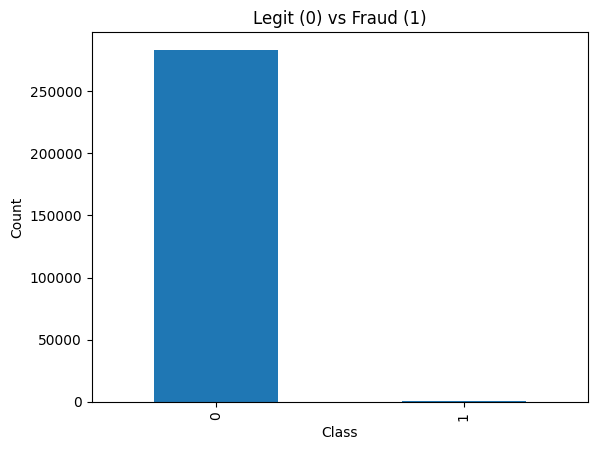

In [16]:
counts = data["Class"].value_counts()
print(counts)
print((counts / len(data) * 100).round(3))

counts.plot(kind="bar")
plt.title("Legit (0) vs Fraud (1)")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

Fraud is very rare (well under 1%), so the data is **imbalanced**. We deal with this later while building the model.

## 5. Outliers in Amount

In [17]:
Q1 = data["Amount"].quantile(0.25)
Q3 = data["Amount"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = data[(data["Amount"] < lower) | (data["Amount"] > upper)]
print("Lower limit:", round(lower, 2), "| Upper limit:", round(upper, 2))
print("Number of outliers:", len(outliers))

Lower limit: -102.27 | Upper limit: 185.38
Number of outliers: 31685


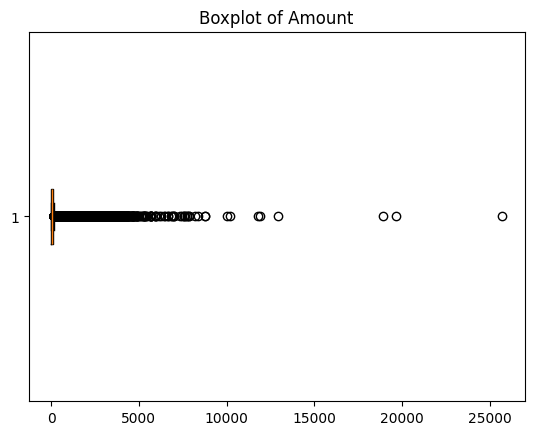

In [18]:
plt.boxplot(data["Amount"], vert=False)
plt.title("Boxplot of Amount")
plt.show()

**Decision: keep the outliers.** Big transactions are normal in real life, and removing them could delete real fraud cases (there are very few). Instead we use a scaler that handles outliers well (next step).

## 6. Scaling

In [19]:
scaler = RobustScaler()
data[["Time", "Amount"]] = scaler.fit_transform(data[["Time", "Amount"]])

data[["Time", "Amount"]].describe()

,Time,Amount
count,283726.000000,283726.000000
mean,0.118912,0.924387
std,0.557988,3.482123
min,-0.995290,-0.305938
25%,-0.358286,-0.228063
50%,0.000000,0.000000
75%,0.641714,0.771937
max,1.035329,356.962314


`V1` to `V28` are already scaled, but `Time` and `Amount` are not, so we scale only those two.

`RobustScaler` is used because `Amount` has many outliers (it uses median and IQR instead of mean).

**Note:** the proper way is to split into train/test first and fit the scaler on train only. Doing it here is fine for practice. If your professor teaches the split first, move this step after it.

## 7. Save cleaned data

In [22]:
data.to_csv("../Data/creditcard_clean.csv", index=False)
print("Saved:", data.shape)

Saved: (283726, 31)


## Summary
- No missing values
- Duplicates removed
- Data is imbalanced (fraud is rare)
- Outliers kept on purpose
- `Time` and `Amount` scaled with RobustScaler
- Cleaned file saved as `creditcard_clean.csv`